# Data Gathering
### import all of the Required Libraries

In [1]:
# %pip install scikit-learn

In [32]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt                       
import seaborn as sns          

import warnings
warnings.filterwarnings('ignore')

In [33]:
# -- URl LINK -> https://www.kaggle.com/datasets/adilshamim8/cost-of-international-education
# csv file name -> International_Education_Costs.csv

import kagglehub
import pandas as pd
from pathlib import Path

# Download the latest dataset
path = kagglehub.dataset_download(
    "adilshamim8/cost-of-international-education"
)

# Find CSV files
dataset_path = Path(path)
csv_files = list(dataset_path.glob("*.csv"))

# Load the first CSV file
if csv_files:
    df = pd.read_csv(csv_files[0])

    print("File loaded:", csv_files[0].name)
    print("\nFirst 5 records:")
    display(df.head())
else:
    print("No CSV file found in the dataset.")

File loaded: International_Education_Costs.csv

First 5 records:


,Country,City,University,Program,Level,Duration_Years,Tuition_USD,Living_Cost_Index,Rent_USD,Visa_Fee_USD,Insurance_USD,Exchange_Rate
0,USA,Cambridge,Harvard University,Computer Science,Master,2.0,55400,83.5,2200,160,1500,1.00
1,UK,London,Imperial College London,Data Science,Master,1.0,41200,75.8,1800,485,800,0.79
2,Canada,Toronto,University of Toronto,Business Analytics,Master,2.0,38500,72.5,1600,235,900,1.35
3,Australia,Melbourne,University of Melbourne,Engineering,Master,2.0,42000,71.2,1400,450,650,1.52
4,Germany,Munich,Technical University of Munich,Mechanical Engineering,Master,2.0,500,70.5,1100,75,550,0.92


In [34]:
# Number of rows and columns
df.shape

(907, 12)

In [35]:
# Column names
df.columns

Index(['Country', 'City', 'University', 'Program', 'Level', 'Duration_Years',
       'Tuition_USD', 'Living_Cost_Index', 'Rent_USD', 'Visa_Fee_USD',
       'Insurance_USD', 'Exchange_Rate'],
      dtype='str')

In [36]:
# Data types and non-null counts
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 907 entries, 0 to 906
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Country            907 non-null    str    
 1   City               907 non-null    str    
 2   University         907 non-null    str    
 3   Program            907 non-null    str    
 4   Level              907 non-null    str    
 5   Duration_Years     907 non-null    float64
 6   Tuition_USD        907 non-null    int64  
 7   Living_Cost_Index  907 non-null    float64
 8   Rent_USD           907 non-null    int64  
 9   Visa_Fee_USD       907 non-null    int64  
 10  Insurance_USD      907 non-null    int64  
 11  Exchange_Rate      907 non-null    float64
dtypes: float64(3), int64(4), str(5)
memory usage: 85.2 KB


In [37]:
# Statistical summary
df.describe()

,Duration_Years,Tuition_USD,Living_Cost_Index,Rent_USD,Visa_Fee_USD,Insurance_USD,Exchange_Rate
count,907.000000,907.000000,907.000000,907.000000,907.000000,907.000000,907.000000
mean,2.836825,16705.016538,64.437486,969.206174,211.396913,700.077178,623.000695
std,0.945449,16582.385275,14.056333,517.154752,143.435740,320.374875,3801.746134
min,1.000000,0.000000,27.800000,150.000000,40.000000,200.000000,0.150000
25%,2.000000,2850.000000,56.300000,545.000000,100.000000,450.000000,0.920000
50%,3.000000,7500.000000,67.500000,900.000000,160.000000,650.000000,1.350000
75%,4.000000,31100.000000,72.200000,1300.000000,240.000000,800.000000,7.150000
max,5.000000,62000.000000,122.400000,2500.000000,490.000000,1500.000000,42150.000000


In [38]:
# Missing values
df.isnull().sum()

Country              0
City                 0
University           0
Program              0
Level                0
Duration_Years       0
Tuition_USD          0
Living_Cost_Index    0
Rent_USD             0
Visa_Fee_USD         0
Insurance_USD        0
Exchange_Rate        0
dtype: int64

In [39]:
# Duplicate records
df.duplicated().sum()

np.int64(0)

In [40]:
text_column  = df.select_dtypes(include='object').columns.to_list()

for col in text_column:
    display(df[col].unique())
    display('--------------------------------------------------------------------------------------------')

<StringArray>
[               'USA',                 'UK',             'Canada',
          'Australia',            'Germany',              'Japan',
        'Netherlands',          'Singapore',             'France',
        'Switzerland',             'Sweden',            'Denmark',
              'China',        'South Korea',            'Ireland',
        'New Zealand',            'Austria',            'Belgium',
          'Hong Kong',           'Portugal',             'Israel',
             'Taiwan',     'Czech Republic',              'India',
             'Poland',           'Malaysia',              'Spain',
              'Italy',            'Finland',             'Norway',
             'Brazil',             'Turkey',             'Russia',
             'Mexico',             'Greece',           'Thailand',
                'UAE',       'South Africa',              'Egypt',
          'Argentina',          'Indonesia',       'Saudi Arabia',
            'Nigeria',            'Vietnam',    

'--------------------------------------------------------------------------------------------'

<StringArray>
['Cambridge',    'London',   'Toronto', 'Melbourne',    'Munich',     'Tokyo',
 'Amsterdam', 'Singapore',     'Paris',    'Zurich',
 ...
 'Cyberjaya',    'Dammam',     'Bangi',      'Taif',    'Melaka',     'Tabuk',
 'Shah Alam',    'Makkah',     'Nilai',   'Al-Ahsa']
Length: 556, dtype: str

'--------------------------------------------------------------------------------------------'

<StringArray>
[              'Harvard University',          'Imperial College London',
            'University of Toronto',          'University of Melbourne',
   'Technical University of Munich',              'University of Tokyo',
          'University of Amsterdam', 'National University of Singapore',
              'Sorbonne University',                       'ETH Zurich',
 ...
      'Imam Abdulrahman University',           'Universidad de Granada',
                              'UKM',                  'Taif University',
                             'UTeM',              'University of Tabuk',
                             'UiTM',           'Umm Al-Qura University',
                             'USIM',           'King Faisal University']
Length: 622, dtype: str

'--------------------------------------------------------------------------------------------'

<StringArray>
[         'Computer Science',              'Data Science',
        'Business Analytics',               'Engineering',
    'Mechanical Engineering',       'Information Science',
   'Artificial Intelligence',                   'Finance',
   'International Relations',                   'Physics',
    'Sustainable Technology',            'Bioinformatics',
      'Computer Engineering',             'Digital Media',
            'Data Analytics',                  'Business',
            'Marine Biology',           'Social Sciences',
       'Biomedical Sciences',     'Aerospace Engineering',
    'Industrial Engineering',      'Chemical Engineering',
               'Mathematics',         'Political Science',
              'Architecture',   'Electronics Engineering',
                  'Medicine',    'Electrical Engineering',
         'Molecular Biology',   'Pharmaceutical Sciences',
                  'Robotics',         'Quantum Computing',
           'Climate Science',             

'--------------------------------------------------------------------------------------------'

<StringArray>
['Master', 'Bachelor', 'PhD']
Length: 3, dtype: str

'--------------------------------------------------------------------------------------------'

In [41]:
number_data = df.select_dtypes(include=['integer','float']).columns.tolist()

for col in number_data:
    display(df[col].agg(['sum','min','max','mean','var','std']))
    display(f"Column Name -> {col}")
    print("-------------------------------------------------------------")

sum     2573.000000
min        1.000000
max        5.000000
mean       2.836825
var        0.893874
std        0.945449
Name: Duration_Years, dtype: float64

'Column Name -> Duration_Years'

-------------------------------------------------------------


sum     1.515145e+07
min     0.000000e+00
max     6.200000e+04
mean    1.670502e+04
var     2.749755e+08
std     1.658239e+04
Name: Tuition_USD, dtype: float64

'Column Name -> Tuition_USD'

...

'Column Name -> Insurance_USD'

-------------------------------------------------------------


sum     5.650616e+05
min     1.500000e-01
max     4.215000e+04
mean    6.230007e+02
var     1.445327e+07
std     3.801746e+03
Name: Exchange_Rate, dtype: float64

'Column Name -> Exchange_Rate'

-------------------------------------------------------------


In [42]:
## astype()---> change the data type of the given column

df['Duration_Years']=df['Duration_Years'].astype('float32')
df['Tuition_USD']=df['Tuition_USD'].astype('int32')
df['Rent_USD']=df['Rent_USD'].astype('int32')
df['Visa_Fee_USD']=df['Visa_Fee_USD'].astype('int32')
df['Insurance_USD']=df['Insurance_USD'].astype('int32')

In [43]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 907 entries, 0 to 906
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Country            907 non-null    str    
 1   City               907 non-null    str    
 2   University         907 non-null    str    
 3   Program            907 non-null    str    
 4   Level              907 non-null    str    
 5   Duration_Years     907 non-null    float32
 6   Tuition_USD        907 non-null    int32  
 7   Living_Cost_Index  907 non-null    float64
 8   Rent_USD           907 non-null    int32  
 9   Visa_Fee_USD       907 non-null    int32  
 10  Insurance_USD      907 non-null    int32  
 11  Exchange_Rate      907 non-null    float64
dtypes: float32(1), float64(2), int32(4), str(5)
memory usage: 67.4 KB


# Exploratory Data Analysis

In [44]:
df["Country"].value_counts().head(10)

Country
UK             93
Australia      86
USA            78
Canada         76
Germany        33
France         27
South Korea    23
Netherlands    21
Switzerland    20
Singapore      18
Name: count, dtype: int64

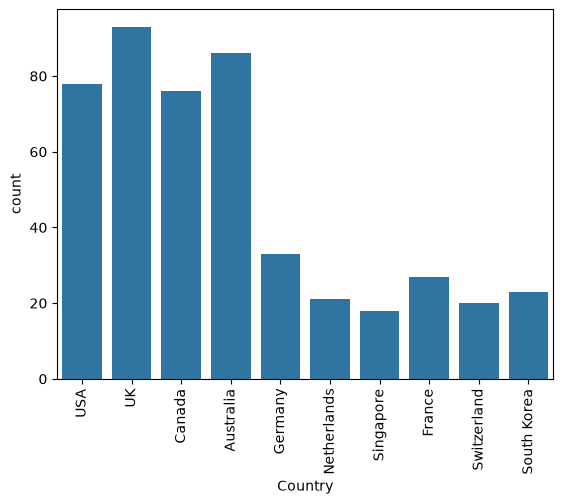

In [45]:
countrys = df[ df["Country"].isin(['UK', 'Australia', 'USA', 'Canada', 'Germany', 'France', 'South Korea', 'Netherlands' , 'Switzerland', 'Singapore']) ]
countrys


sns.countplot(data = countrys, x = 'Country')
plt.xticks(rotation = 'vertical')
plt.show()

In [46]:
df["City"].value_counts().head()

City
Singapore    18
Melbourne    11
Sydney       11
London       10
Canberra      8
Name: count, dtype: int64

<Axes: xlabel='Level', ylabel='count'>

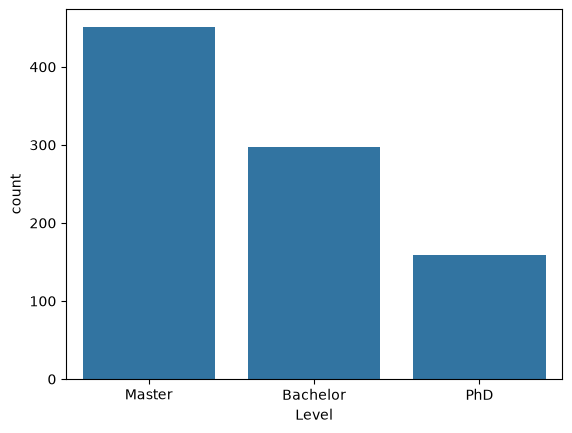

In [47]:
city=df[df['City'].isin([ 'Singapore', 'Melbourne', 'Sydney', 'London', 'Canberra'])]
city

sns.countplot(data = df, x = 'Level')

In [48]:
df["Duration_Years"].value_counts()

Duration_Years
2.0    423
4.0    276
3.0    171
5.0     17
1.0     16
2.5      3
1.5      1
Name: count, dtype: int64

<Axes: xlabel='Duration_Years', ylabel='Count'>

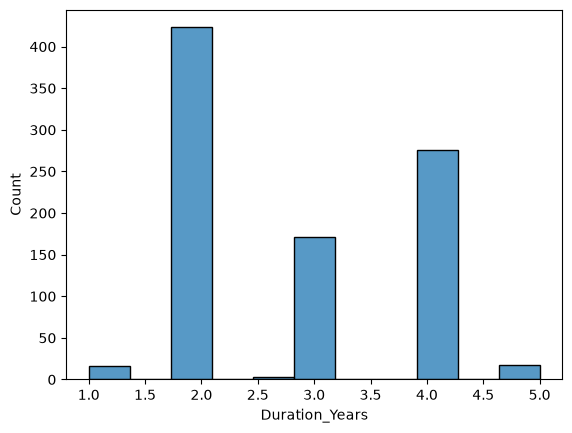

In [49]:
sns.histplot(data = df, x = "Duration_Years")

<Axes: xlabel='Tuition_USD', ylabel='Count'>

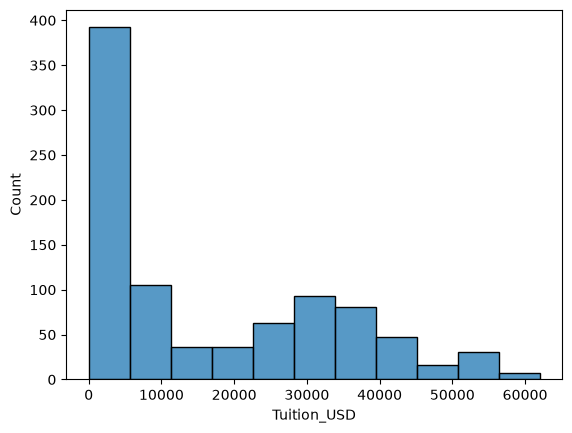

In [50]:
sns.histplot(data = df, x  = 'Tuition_USD')

<Axes: xlabel='Rent_USD', ylabel='Density'>

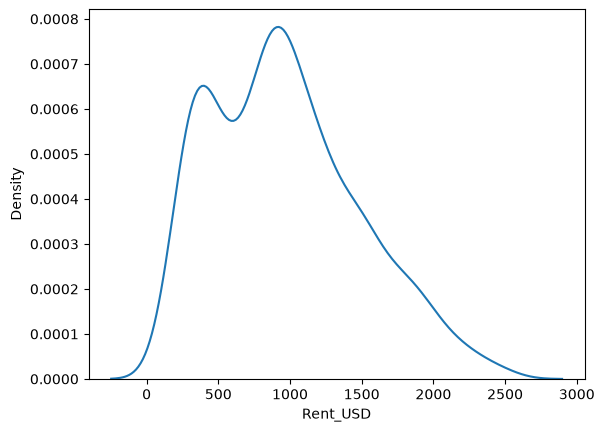

In [51]:
sns.kdeplot(data = df, x = 'Rent_USD' )

<Axes: xlabel='Rent_USD'>

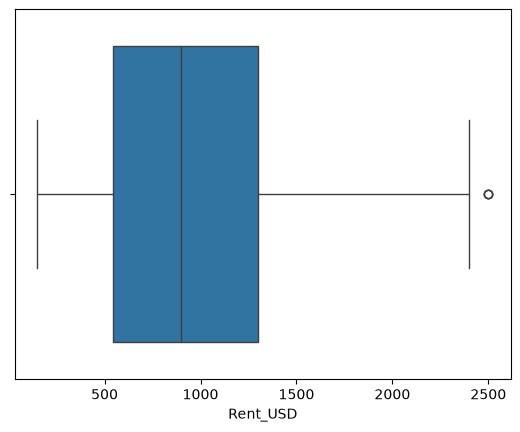

In [52]:
sns.boxplot(data = df, x = 'Rent_USD')

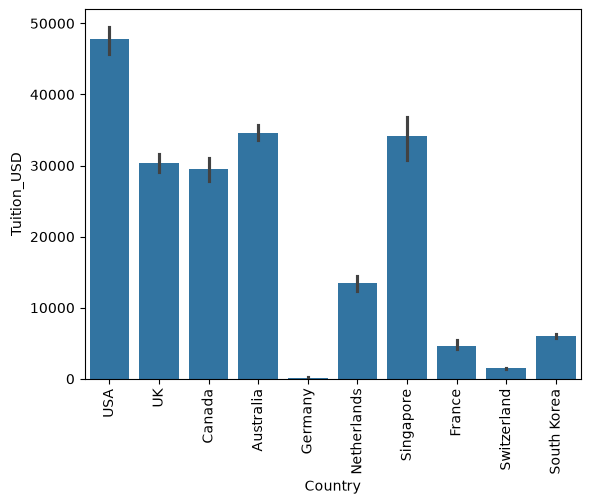

In [53]:
sns.barplot(data= countrys, x='Country', y='Tuition_USD')
plt.xticks(rotation="vertical")
plt.show()

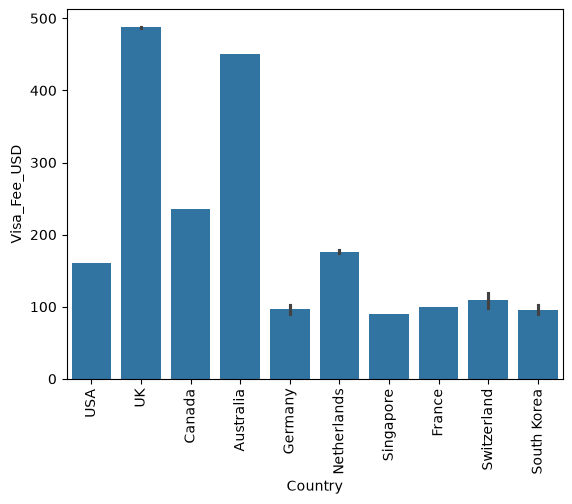

In [54]:
sns.barplot(data= countrys, x='Country', y='Visa_Fee_USD')
plt.xticks(rotation="vertical")
plt.show()

In [55]:
df['University'].value_counts().head(10).index

Index(['University of Washington', 'University of Melbourne',
       'Stanford University', 'Australian National University',
       'University of Sydney', 'University of Adelaide',
       'University of Western Australia', 'Griffith University',
       'University of Tasmania', 'University of Newcastle'],
      dtype='str', name='University')

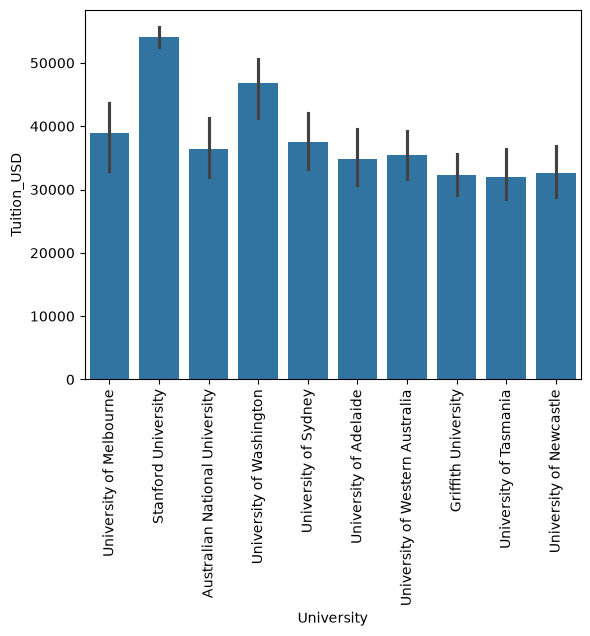

In [56]:
university=df[df['University'].isin(df['University'].value_counts().head(10).index) ]

sns.barplot(data=university,x='University',y='Tuition_USD')
plt.xticks(rotation='vertical')
plt.show()

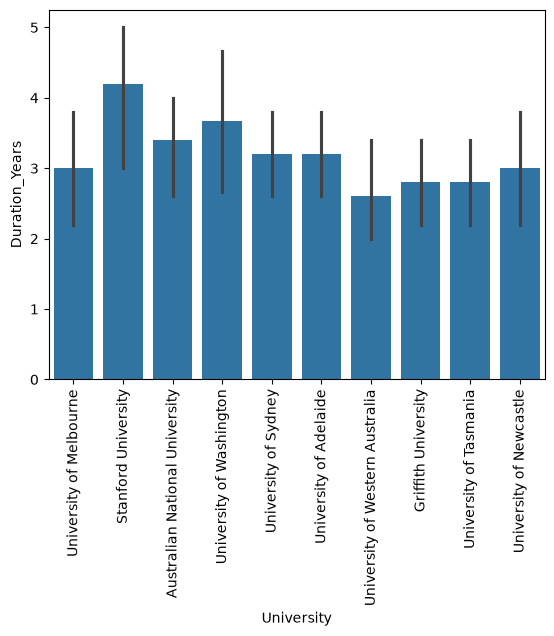

In [57]:
university=df[df['University'].isin(df['University'].value_counts().head(10).index) ]


sns.barplot(data =university,x= 'University',y='Duration_Years')
plt.xticks(rotation=90)
plt.show()

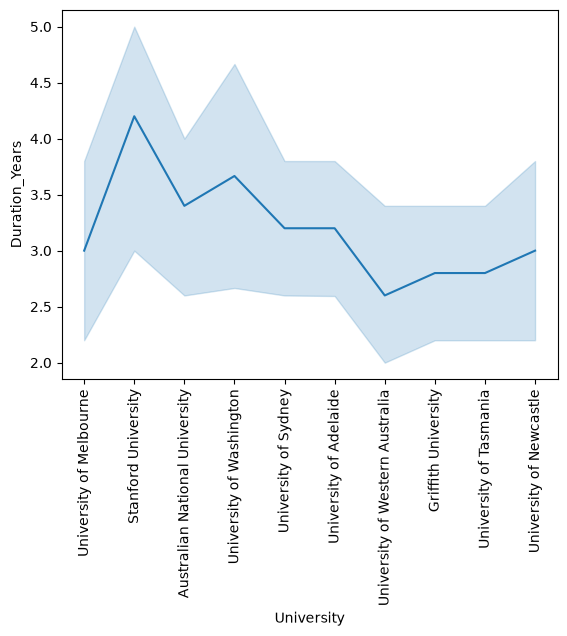

In [58]:
university=df[df['University'].isin(df['University'].value_counts().head(10).index) ]


sns.lineplot(data =university,x= 'University',y='Duration_Years')
plt.xticks(rotation=90)
plt.show()

### Top 10 Country ---> Top 10 Universities --> Tuition Fees ( Heatmap )

In [59]:
top_10_Country = df["Country"].value_counts().head(10)
display(top_10_Country)

top_10_University = df["University"].value_counts().head(10)
top_10_University

Country
UK             93
Australia      86
USA            78
Canada         76
Germany        33
France         27
South Korea    23
Netherlands    21
Switzerland    20
Singapore      18
Name: count, dtype: int64

University
University of Washington           6
University of Melbourne            5
Stanford University                5
Australian National University     5
University of Sydney               5
University of Adelaide             5
University of Western Australia    5
Griffith University                5
University of Tasmania             5
University of Newcastle            5
Name: count, dtype: int64

<Axes: xlabel='University', ylabel='Country'>

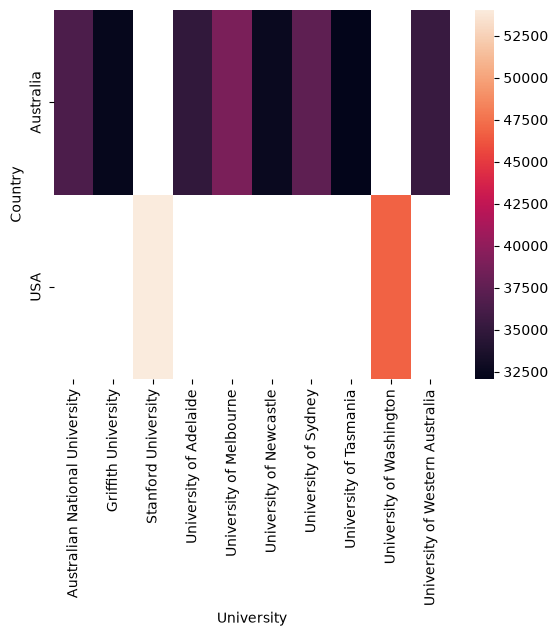

In [60]:
university = df[ df["University"].isin(top_10_University.index) ]

data = university.pivot_table(index='Country', columns="University", values='Tuition_USD', aggfunc='mean')
data

sns.heatmap(data)

# Feature Engineering

In [65]:
df["Total_cost"] = df["Tuition_USD"] + df["Rent_USD"]
df

,Country,City,University,Program,Level,Duration_Years,Tuition_USD,Living_Cost_Index,Rent_USD,Visa_Fee_USD,Insurance_USD,Exchange_Rate,Total_cost
0,USA,Cambridge,Harvard University,Computer Science,Master,2.0,55400,83.5,2200,160,1500,1.00,57600
1,UK,London,Imperial College London,Data Science,Master,1.0,41200,75.8,1800,485,800,0.79,43000
2,Canada,Toronto,University of Toronto,Business Analytics,Master,2.0,38500,72.5,1600,235,900,1.35,40100
3,Australia,Melbourne,University of Melbourne,Engineering,Master,2.0,42000,71.2,1400,450,650,1.52,43400
4,Germany,Munich,Technical University of Munich,Mechanical Engineering,Master,2.0,500,70.5,1100,75,550,0.92,1600
...,...,...,...,...,...,...,...,...,...,...,...,...,...
902,France,Strasbourg,University of Strasbourg,Data Analytics,Master,2.0,4000,70.2,1000,99,850,0.92,5000
903,Malaysia,Nilai,USIM,Computer Science,Bachelor,3.0,6800,50.5,400,120,400,4.65,7200
904,Saudi Arabia,Al-Ahsa,King Faisal University,Information Systems,Master,2.0,4200,64.2,600,200,800,3.75,4800
905,USA,Seattle,University of Washington,Software Development,PhD,5.0,50000,77.8,2000,160,1500,1.00,52000


# Feature Selection

In [66]:
df.columns

Index(['Country', 'City', 'University', 'Program', 'Level', 'Duration_Years',
       'Tuition_USD', 'Living_Cost_Index', 'Rent_USD', 'Visa_Fee_USD',
       'Insurance_USD', 'Exchange_Rate', 'Total_cost'],
      dtype='str')

In [67]:
df = df[['Country', 'City', 'University', 'Program', 'Level', 'Duration_Years',
'Living_Cost_Index',  'Visa_Fee_USD','Insurance_USD', 'Total_cost']]
df

,Country,City,University,Program,Level,Duration_Years,Living_Cost_Index,Visa_Fee_USD,Insurance_USD,Total_cost
0,USA,Cambridge,Harvard University,Computer Science,Master,2.0,83.5,160,1500,57600
1,UK,London,Imperial College London,Data Science,Master,1.0,75.8,485,800,43000
2,Canada,Toronto,University of Toronto,Business Analytics,Master,2.0,72.5,235,900,40100
3,Australia,Melbourne,University of Melbourne,Engineering,Master,2.0,71.2,450,650,43400
4,Germany,Munich,Technical University of Munich,Mechanical Engineering,Master,2.0,70.5,75,550,1600
...,...,...,...,...,...,...,...,...,...,...
902,France,Strasbourg,University of Strasbourg,Data Analytics,Master,2.0,70.2,99,850,5000
903,Malaysia,Nilai,USIM,Computer Science,Bachelor,3.0,50.5,120,400,7200
904,Saudi Arabia,Al-Ahsa,King Faisal University,Information Systems,Master,2.0,64.2,200,800,4800
905,USA,Seattle,University of Washington,Software Development,PhD,5.0,77.8,160,1500,52000


# Feature Encodimg
- 1) Lable Encoder
- 2) Ordinal Encoder
- 3) One-Hot Encoder

In [78]:
from sklearn.preprocessing import LabelEncoder, OrdinalEncoder, OneHotEncoder

le = LabelEncoder()
od = OrdinalEncoder()
one = OneHotEncoder()

df["Country"] = le.fit_transform(df["Country"])
df["City"] = le.fit_transform(df["City"])
df["Program"] = le.fit_transform(df["Program"])
df["Level"] = le.fit_transform(df["Level"])
df["University"] = le.fit_transform(df["University"])


In [79]:
df.iloc[:, :9]

,Country,City,University,Program,Level,Duration_Years,Living_Cost_Index,Visa_Fee_USD,Insurance_USD
0,66,84,101,17,1,2.0,83.5,160,1500
1,65,283,128,27,1,1.0,75.8,485,800
2,9,503,572,9,1,2.0,72.5,235,900
3,2,313,495,44,1,2.0,71.2,450,650
4,22,330,307,66,1,2.0,70.5,75,550
...,...,...,...,...,...,...,...,...,...
902,21,469,556,25,1,2.0,70.2,99,850
903,38,344,345,17,0,3.0,50.5,120,400
904,51,12,154,57,1,2.0,64.2,200,800
905,66,441,585,84,2,5.0,77.8,160,1500


In [80]:
X = df.drop(columns="Total_cost")
Y = df["Total_cost"]

In [81]:
X

,Country,City,University,Program,Level,Duration_Years,Living_Cost_Index,Visa_Fee_USD,Insurance_USD
0,66,84,101,17,1,2.0,83.5,160,1500
1,65,283,128,27,1,1.0,75.8,485,800
2,9,503,572,9,1,2.0,72.5,235,900
3,2,313,495,44,1,2.0,71.2,450,650
4,22,330,307,66,1,2.0,70.5,75,550
...,...,...,...,...,...,...,...,...,...
902,21,469,556,25,1,2.0,70.2,99,850
903,38,344,345,17,0,3.0,50.5,120,400
904,51,12,154,57,1,2.0,64.2,200,800
905,66,441,585,84,2,5.0,77.8,160,1500


# Scale The Data

In [85]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler, Normalizer

ss = StandardScaler()

X  = ss.fit_transform(X)
x

,Country,City,University,Program,Level,Duration_Years,Living_Cost_Index,Visa_Fee_USD,Insurance_USD
0,66,84,101,17,1,2.0,83.5,160,1500
1,65,283,128,27,1,1.0,75.8,485,800
2,9,503,572,9,1,2.0,72.5,235,900
3,2,313,495,44,1,2.0,71.2,450,650
4,22,330,307,66,1,2.0,70.5,75,550
...,...,...,...,...,...,...,...,...,...
902,21,469,556,25,1,2.0,70.2,99,850
903,38,344,345,17,0,3.0,50.5,120,400
904,51,12,154,57,1,2.0,64.2,200,800
905,66,441,585,84,2,5.0,77.8,160,1500


In [88]:
from sklearn.model_selection import train_test_split

X_train, X_test, Y_train, Y_test = train_test_split(X,Y, test_size=0.2, random_state=42)

display(X_train.shape)
display(Y_train.shape)
display(X_test.shape)
display(Y_test.shape)

(725, 9)

(725,)

(182, 9)

(182,)

Dataset loaded successfully!
File: International_Education_Costs.csv

First 5 records:


,Country,City,University,Program,Level,Duration_Years,Tuition_USD,Living_Cost_Index,Rent_USD,Visa_Fee_USD,Insurance_USD,Exchange_Rate
0,USA,Cambridge,Harvard University,Computer Science,Master,2.0,55400,83.5,2200,160,1500,1.00
1,UK,London,Imperial College London,Data Science,Master,1.0,41200,75.8,1800,485,800,0.79
2,Canada,Toronto,University of Toronto,Business Analytics,Master,2.0,38500,72.5,1600,235,900,1.35
3,Australia,Melbourne,University of Melbourne,Engineering,Master,2.0,42000,71.2,1400,450,650,1.52
4,Germany,Munich,Technical University of Munich,Mechanical Engineering,Master,2.0,500,70.5,1100,75,550,0.92



Last 5 records:


,Country,City,University,Program,Level,Duration_Years,Tuition_USD,Living_Cost_Index,Rent_USD,Visa_Fee_USD,Insurance_USD,Exchange_Rate
902,France,Strasbourg,University of Strasbourg,Data Analytics,Master,2.0,4000,70.2,1000,99,850,0.92
903,Malaysia,Nilai,USIM,Computer Science,Bachelor,3.0,6800,50.5,400,120,400,4.65
904,Saudi Arabia,Al-Ahsa,King Faisal University,Information Systems,Master,2.0,4200,64.2,600,200,800,3.75
905,USA,Seattle,University of Washington,Software Development,PhD,5.0,50000,77.8,2000,160,1500,1.00
906,UK,Nottingham,University of Nottingham,Data Engineering,Master,2.0,34000,61.2,800,485,800,0.79



Dataset shape:
(907, 12)

Column names:
['Country', 'City', 'University', 'Program', 'Level', 'Duration_Years', 'Tuition_USD', 'Living_Cost_Index', 'Rent_USD', 'Visa_Fee_USD', 'Insurance_USD', 'Exchange_Rate']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 907 entries, 0 to 906
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Country            907 non-null    str    
 1   City               907 non-null    str    
 2   University         907 non-null    str    
 3   Program            907 non-null    str    
 4   Level              907 non-null    str    
 5   Duration_Years     907 non-null    float64
 6   Tuition_USD        907 non-null    int64  
 7   Living_Cost_Index  907 non-null    float64
 8   Rent_USD           907 non-null    int64  
 9   Visa_Fee_USD       907 non-null    int64  
 10  Insurance_USD      907 non-null    int64  
 11  Exchange_Rate      907 non-null    float64
d

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Country,907,71,UK,93,NaN,NaN,NaN,NaN,NaN,NaN,NaN
City,907,556,Singapore,18,NaN,NaN,NaN,NaN,NaN,NaN,NaN
University,907,622,University of Washington,6,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Program,907,92,Computer Science,312,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Level,907,3,Master,451,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Duration_Years,907.0,NaN,NaN,NaN,2.836825,0.945449,1.0,2.0,3.0,4.0,5.0
Tuition_USD,907.0,NaN,NaN,NaN,16705.016538,16582.385275,0.0,2850.0,7500.0,31100.0,62000.0
Living_Cost_Index,907.0,NaN,NaN,NaN,64.437486,14.056333,27.8,56.3,67.5,72.2,122.4
Rent_USD,907.0,NaN,NaN,NaN,969.206174,517.154752,150.0,545.0,900.0,1300.0,2500.0
Visa_Fee_USD,907.0,NaN,NaN,NaN,211.396913,143.43574,40.0,100.0,160.0,240.0,490.0



Missing values:
Country              0
City                 0
University           0
Program              0
Level                0
Duration_Years       0
Tuition_USD          0
Living_Cost_Index    0
Rent_USD             0
Visa_Fee_USD         0
Insurance_USD        0
Exchange_Rate        0
dtype: int64

Duplicate records: 0

Unique values in each column:
Country: 71
City: 556
University: 622
Program: 92
Level: 3
Duration_Years: 7
Tuition_USD: 274
Living_Cost_Index: 225
Rent_USD: 67
Visa_Fee_USD: 30
Insurance_USD: 20
Exchange_Rate: 65

Cleaned dataset shape: (907, 12)

Missing values after cleaning:
Country              0
City                 0
University           0
Program              0
Level                0
Duration_Years       0
Tuition_USD          0
Living_Cost_Index    0
Rent_USD             0
Visa_Fee_USD         0
Insurance_USD        0
Exchange_Rate        0
dtype: int64


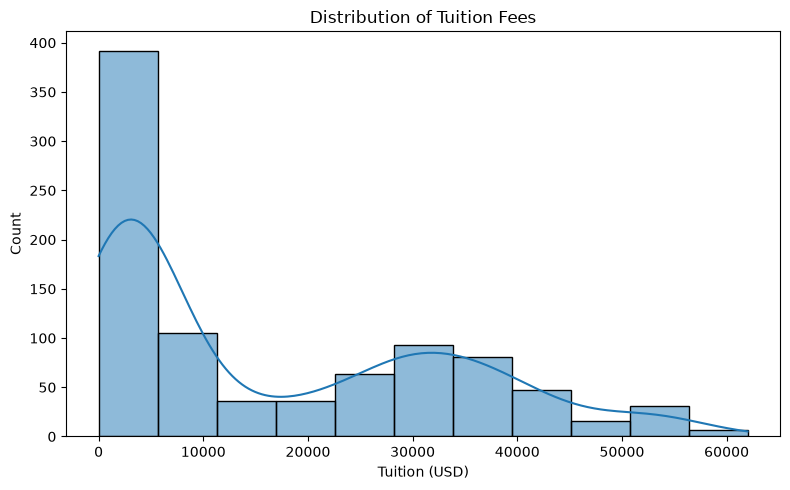

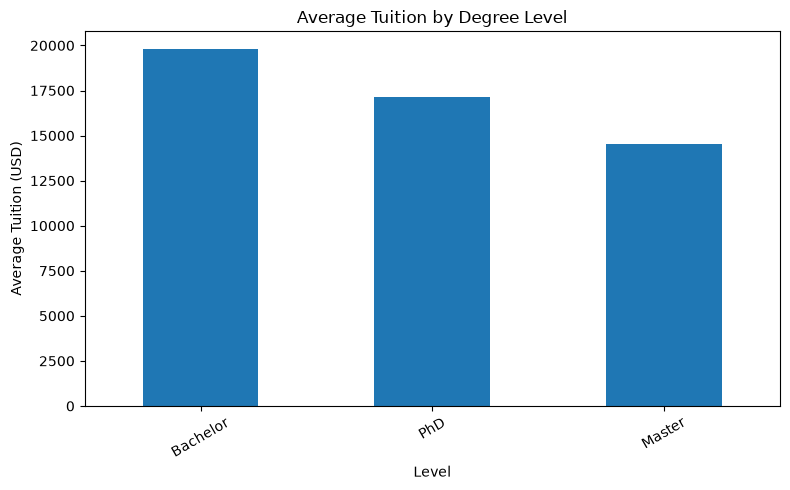

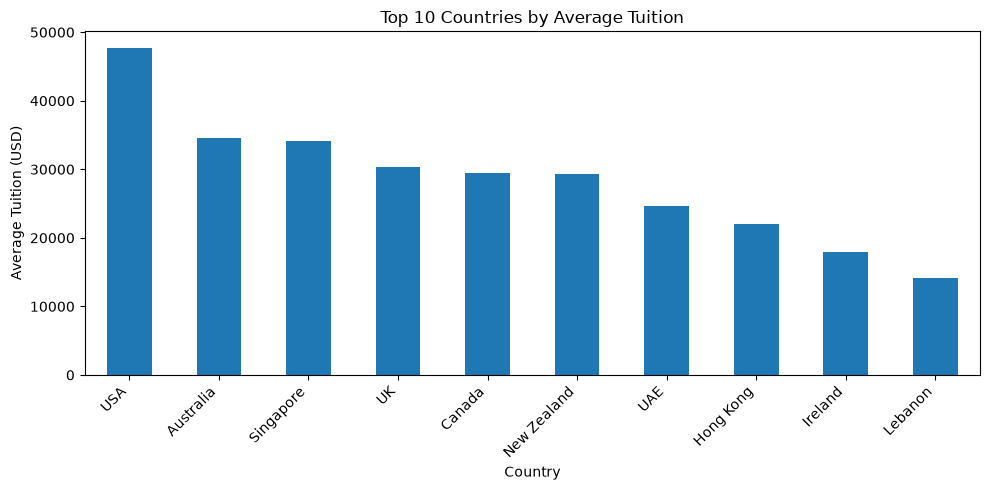

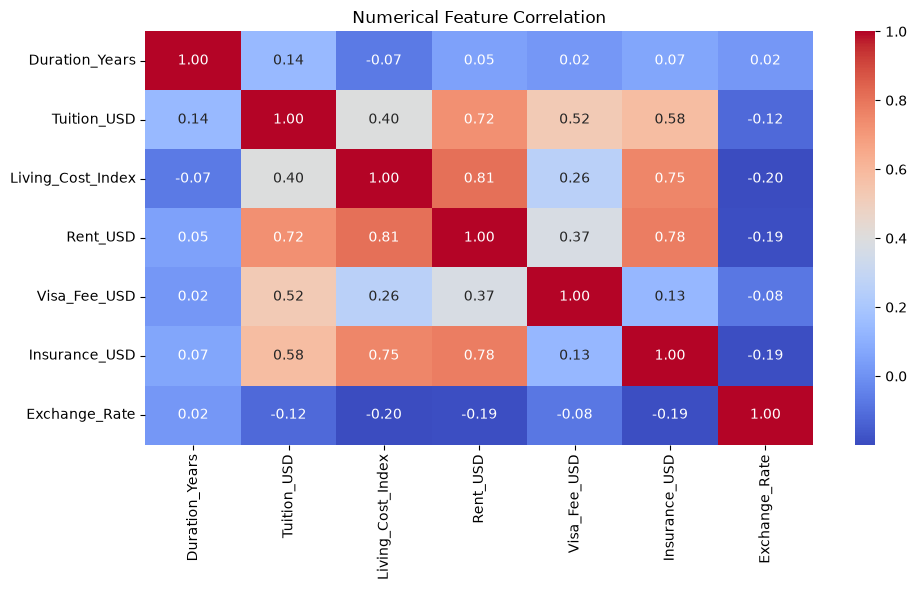


Numerical features:
['Duration_Years', 'Living_Cost_Index', 'Rent_USD', 'Visa_Fee_USD', 'Insurance_USD', 'Exchange_Rate']

Categorical features:
['Country', 'City', 'University', 'Program', 'Level']

Target variable: Tuition_USD

Training records: 725
Testing records: 182

Preprocessing pipeline created successfully.

Training: Linear Regression
MAE: $4,012.53
RMSE: $5,237.44
R2 Score: 0.8948

Training: Random Forest
MAE: $1,913.49
RMSE: $3,198.17
R2 Score: 0.9608

Training: Gradient Boosting
MAE: $4,608.74
RMSE: $5,915.61
R2 Score: 0.8659

MODEL COMPARISON


,Model,MAE,RMSE,R2 Score
0,Random Forest,1913.4907,3198.1699,0.9608
1,Linear Regression,4012.5281,5237.4392,0.8948
2,Gradient Boosting,4608.7445,5915.6115,0.8659


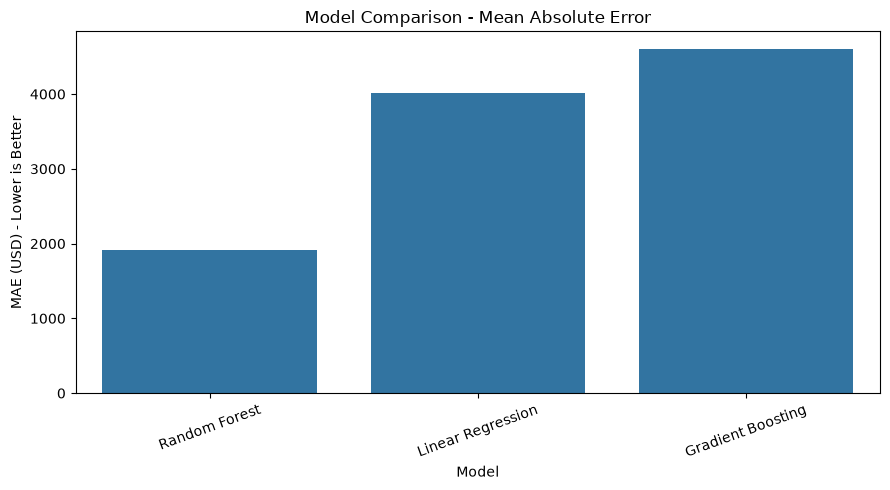


Best model based on test MAE: Random Forest

Cross-validation MAE scores:
[1918.3  2404.14 2102.7  2318.74 2352.5 ]
Mean CV MAE: $ 2219.28
Std CV MAE: $ 182.21

Actual vs Predicted:


,Actual_Tuition_USD,Predicted_Tuition_USD,Absolute_Error
0,7000,6966.13,33.87
1,0,0.00,0.00
2,34000,30562.87,3437.13
3,7500,6890.31,609.69
4,2000,14650.25,12650.25
5,2700,3788.29,1088.29
6,0,1969.65,1969.65
7,24100,21564.68,2535.32
8,4000,4187.07,187.07
9,0,18.75,18.75


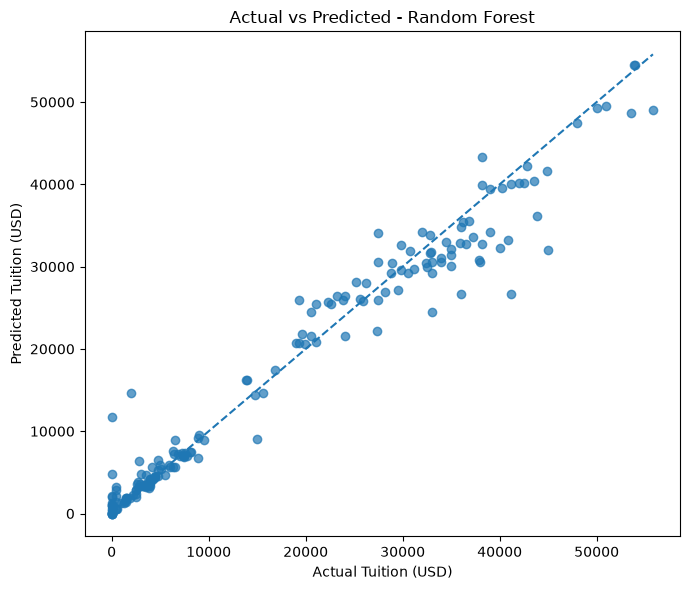


Model saved successfully: D:\Practice\best_tuition_model.joblib
Evaluation metrics saved.
Test predictions saved.

Saved model loaded successfully.

NEW TUITION PREDICTION
Country: USA
Program: Data Science
Level: Master
Predicted tuition: $55,210.73 USD

PROJECT COMPLETED SUCCESSFULLY!


In [31]:

# ============================================================
# PROJECT: COST OF INTERNATIONAL EDUCATION - ML PIPELINE
# TARGET: Tuition_USD
# ============================================================

# 1. IMPORT LIBRARIES
import kagglehub
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from pathlib import Path

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import warnings
warnings.filterwarnings("ignore")

RANDOM_STATE = 42

# ============================================================
# 2. DOWNLOAD DATASET
# ============================================================

path = kagglehub.dataset_download(
    "adilshamim8/cost-of-international-education"
)

csv_files = list(Path(path).rglob("*.csv"))

if not csv_files:
    raise FileNotFoundError("No CSV file found in the dataset.")

csv_file = next(
    (f for f in csv_files
     if f.name == "International_Education_Costs.csv"),
    csv_files[0]
)

df = pd.read_csv(csv_file)

print("Dataset loaded successfully!")
print("File:", csv_file.name)

# ============================================================
# 3. BASIC DATA EXPLORATION
# ============================================================

print("\nFirst 5 records:")
display(df.head())

print("\nLast 5 records:")
display(df.tail())

print("\nDataset shape:")
print(df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nStatistical summary:")
display(df.describe(include="all").T)

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate records:", df.duplicated().sum())

print("\nUnique values in each column:")
for col in df.columns:
    print(f"{col}: {df[col].nunique(dropna=True)}")

# ============================================================
# 4. DATA CLEANING
# ============================================================

# Remove extra spaces from column names
df.columns = df.columns.str.strip()

# Remove duplicate records
df = df.drop_duplicates().copy()

# Remove extra spaces from text columns
for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].str.strip()

# Convert expected numerical columns to numeric
numeric_candidates = [
    "Duration_Years",
    "Tuition_USD",
    "Living_Cost_Index",
    "Rent_USD",
    "Visa_Fee_USD",
    "Insurance_USD",
    "Exchange_Rate"
]

for col in numeric_candidates:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

# Check required target column
TARGET = "Tuition_USD"

if TARGET not in df.columns:
    raise ValueError(
        f"Target column '{TARGET}' not found. "
        f"Available columns: {df.columns.tolist()}"
    )

# Target cannot be missing for supervised learning
df = df.dropna(subset=[TARGET]).copy()

# Remove invalid target values
df = df[df[TARGET] >= 0].copy()

print("\nCleaned dataset shape:", df.shape)
print("\nMissing values after cleaning:")
print(df.isnull().sum())

# ============================================================
# 5. EXPLORATORY DATA ANALYSIS (EDA)
# ============================================================

# Tuition distribution
plt.figure(figsize=(8, 5))
sns.histplot(df[TARGET], kde=True)
plt.title("Distribution of Tuition Fees")
plt.xlabel("Tuition (USD)")
plt.tight_layout()
plt.show()

# Average tuition by degree level
if "Level" in df.columns:
    level_tuition = (
        df.groupby("Level")[TARGET]
        .mean()
        .sort_values(ascending=False)
    )

    level_tuition.plot(kind="bar", figsize=(8, 5))
    plt.title("Average Tuition by Degree Level")
    plt.ylabel("Average Tuition (USD)")
    plt.xticks(rotation=30)
    plt.tight_layout()
    plt.show()

# Top 10 countries by average tuition
if "Country" in df.columns:
    country_tuition = (
        df.groupby("Country")[TARGET]
        .mean()
        .sort_values(ascending=False)
        .head(10)
    )

    country_tuition.plot(kind="bar", figsize=(10, 5))
    plt.title("Top 10 Countries by Average Tuition")
    plt.ylabel("Average Tuition (USD)")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

# Correlation heatmap for numeric variables
numeric_df = df.select_dtypes(include=np.number)

if len(numeric_df.columns) > 1:
    plt.figure(figsize=(10, 6))
    sns.heatmap(
        numeric_df.corr(),
        annot=True,
        cmap="coolwarm",
        fmt=".2f"
    )
    plt.title("Numerical Feature Correlation")
    plt.tight_layout()
    plt.show()

# ============================================================
# 6. DEFINE FEATURES (X) AND TARGET (y)
# ============================================================

# Predict tuition using all other available columns.
# Tuition_USD is excluded from X to prevent target leakage.

X = df.drop(columns=[TARGET])
y = df[TARGET]

# Exclude any additional columns that directly reveal tuition,
# such as a precomputed tuition copy, if present in another version.
leakage_columns = [
    col for col in X.columns
    if col.lower() in [
        "tuition",
        "tuition_fee",
        "tuition_fee_usd"
    ]
]

X = X.drop(columns=leakage_columns, errors="ignore")

# Identify numerical and categorical features
numeric_features = X.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X.select_dtypes(
    exclude=np.number
).columns.tolist()

print("\nNumerical features:")
print(numeric_features)

print("\nCategorical features:")
print(categorical_features)

print("\nTarget variable:", TARGET)

# ============================================================
# 7. TRAIN-TEST SPLIT
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE
)

print("\nTraining records:", X_train.shape[0])
print("Testing records:", X_test.shape[0])

# ============================================================
# 8. DATA PREPROCESSING PIPELINE
# ============================================================

# Numerical preprocessing:
# 1. Fill missing values with median
# 2. Scale numerical features

numeric_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

# Categorical preprocessing:
# 1. Fill missing values with most frequent value
# 2. Convert categories into numerical columns

categorical_pipeline = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="most_frequent")
        ),
        (
            "encoder",
            OneHotEncoder(handle_unknown="ignore")
        )
    ]
)

# Combine both preprocessing pipelines
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_pipeline, numeric_features),
        ("cat", categorical_pipeline, categorical_features)
    ]
)

print("\nPreprocessing pipeline created successfully.")

# ============================================================
# 9. BUILD MULTIPLE MACHINE LEARNING MODELS
# ============================================================

models = {
    "Linear Regression": LinearRegression(),

    "Random Forest": RandomForestRegressor(
        n_estimators=200,
        random_state=RANDOM_STATE,
        min_samples_leaf=2,
        n_jobs=-1
    ),

    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=100,
        learning_rate=0.05,
        max_depth=2,
        random_state=RANDOM_STATE
    )
}

# ============================================================
# 10. TRAIN AND EVALUATE MODELS
# ============================================================

results = []
trained_models = {}

for model_name, model in models.items():

    print(f"\nTraining: {model_name}")

    # Complete pipeline: preprocessing + ML algorithm
    pipeline = Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            ("model", model)
        ]
    )

    # Train the model
    pipeline.fit(X_train, y_train)

    # Predict on unseen test records
    y_pred = pipeline.predict(X_test)

    # Calculate evaluation metrics
    mae = mean_absolute_error(y_test, y_pred)

    rmse = np.sqrt(
        mean_squared_error(y_test, y_pred)
    )

    r2 = r2_score(y_test, y_pred)

    results.append({
        "Model": model_name,
        "MAE": mae,
        "RMSE": rmse,
        "R2 Score": r2
    })

    trained_models[model_name] = pipeline

    print(f"MAE: ${mae:,.2f}")
    print(f"RMSE: ${rmse:,.2f}")
    print(f"R2 Score: {r2:.4f}")

# ============================================================
# 11. COMPARE MODELS
# ============================================================

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="MAE",
    ascending=True
).reset_index(drop=True)

print("\nMODEL COMPARISON")
display(results_df.round(4))

# Visual comparison
plt.figure(figsize=(9, 5))
sns.barplot(
    data=results_df,
    x="Model",
    y="MAE"
)
plt.title("Model Comparison - Mean Absolute Error")
plt.ylabel("MAE (USD) - Lower is Better")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

# ============================================================
# 12. SELECT THE BEST MODEL
# ============================================================

best_model_name = results_df.iloc[0]["Model"]
best_model = trained_models[best_model_name]

print("\nBest model based on test MAE:", best_model_name)

# ============================================================
# 13. CROSS-VALIDATION
# ============================================================

# Cross-validation on the training data only.
# All preprocessing is fitted independently in each fold.

cv_scores = cross_val_score(
    best_model,
    X_train,
    y_train,
    cv=5,
    scoring="neg_mean_absolute_error",
    n_jobs=-1
)

cv_mae_scores = -cv_scores

print("\nCross-validation MAE scores:")
print(np.round(cv_mae_scores, 2))

print("Mean CV MAE: $", round(cv_mae_scores.mean(), 2))
print("Std CV MAE: $", round(cv_mae_scores.std(), 2))

# ============================================================
# 14. ACTUAL VS PREDICTED VALUES
# ============================================================

best_predictions = best_model.predict(X_test)

comparison_df = pd.DataFrame({
    "Actual_Tuition_USD": y_test.to_numpy(),
    "Predicted_Tuition_USD": best_predictions
})

comparison_df["Absolute_Error"] = abs(
    comparison_df["Actual_Tuition_USD"]
    - comparison_df["Predicted_Tuition_USD"]
)

print("\nActual vs Predicted:")
display(comparison_df.head(10).round(2))

# Scatter plot
plt.figure(figsize=(7, 6))
plt.scatter(
    comparison_df["Actual_Tuition_USD"],
    comparison_df["Predicted_Tuition_USD"],
    alpha=0.7
)

plt.xlabel("Actual Tuition (USD)")
plt.ylabel("Predicted Tuition (USD)")
plt.title(f"Actual vs Predicted - {best_model_name}")

# Reference line
min_value = min(
    comparison_df["Actual_Tuition_USD"].min(),
    comparison_df["Predicted_Tuition_USD"].min()
)

max_value = max(
    comparison_df["Actual_Tuition_USD"].max(),
    comparison_df["Predicted_Tuition_USD"].max()
)

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.tight_layout()
plt.show()

# ============================================================
# 15. SAVE THE COMPLETE PIPELINE
# ============================================================

model_path = Path("best_tuition_model.joblib")

joblib.dump(best_model, model_path)

print("\nModel saved successfully:", model_path.resolve())

# Save comparison metrics
results_df.to_csv(
    "model_comparison_results.csv",
    index=False
)

# Save test predictions
comparison_df.to_csv(
    "tuition_predictions.csv",
    index=False
)

print("Evaluation metrics saved.")
print("Test predictions saved.")

# ============================================================
# 16. LOAD THE SAVED MODEL
# ============================================================

loaded_model = joblib.load(model_path)

print("\nSaved model loaded successfully.")

# ============================================================
# 17. PREDICT TUITION FOR A NEW RECORD
# ============================================================

# Use a real record from the dataset as a template.
# Replace the values with the university and study details
# you want to evaluate.

new_student = X.iloc[[0]].copy()

# Example: modify selected features if they exist
if "Country" in new_student.columns:
    new_student.loc[:, "Country"] = "USA"

if "City" in new_student.columns:
    new_student.loc[:, "City"] = "Boston"

if "Program" in new_student.columns:
    new_student.loc[:, "Program"] = "Data Science"

if "Level" in new_student.columns:
    new_student.loc[:, "Level"] = "Master"

if "Duration_Years" in new_student.columns:
    new_student.loc[:, "Duration_Years"] = 2

# Predict tuition using the saved pipeline
predicted_tuition = loaded_model.predict(new_student)[0]

print("\nNEW TUITION PREDICTION")
print("Country:", new_student["Country"].iloc[0]
      if "Country" in new_student.columns else "N/A")
print("Program:", new_student["Program"].iloc[0]
      if "Program" in new_student.columns else "N/A")
print("Level:", new_student["Level"].iloc[0]
      if "Level" in new_student.columns else "N/A")
print(f"Predicted tuition: ${predicted_tuition:,.2f} USD")

print("\nPROJECT COMPLETED SUCCESSFULLY!")
